## DFT TESTBENCH

This notebook takes two inputs (real and imaginary) and gived the real and imaginary parts of the DFT outputs using AXI-STREAM. It is then compared with software version of FFT

In [1]:
from pynq import Overlay
import numpy as np
from pynq import allocate
import pynq.buffer as pb
import matplotlib.pyplot as plt

# NumPy >= 2 added a read-only ndarray.device, which PynqBuffer tries to assign.
# Shadow it with a normal read/write attribute on the subclass (only needed on NumPy 2).
if int(np.__version__.split('.')[0]) >= 2:
    pb.PynqBuffer.device = property(lambda self: getattr(self, "_pynq_device", None),
                                    lambda self, v: setattr(self, "_pynq_device", v))

/usr/local/share/pynq-venv/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


In [2]:
ol = Overlay('dft.bit')

# list the DMAs actually present in the bitstream
print([n for n, d in ol.ip_dict.items() if 'axi_dma' in d['type']])

['axi_dma_in_stream', 'axi_dma_out_stream']


In [3]:
dma_in  = ol.axi_dma_in_stream      # MM2S only: DDR -> DFT
dma_out = ol.axi_dma_out_stream     # S2MM only: DFT -> DDR
dft_ip  = ol.dft_0

In [4]:
NUM_SAMPLES = 1024

real_error=np.zeros(NUM_SAMPLES)
imag_error=np.zeros(NUM_SAMPLES)
ind=np.arange(NUM_SAMPLES)
real_rmse=np.zeros(NUM_SAMPLES)
imag_rmse=np.zeros(NUM_SAMPLES)

In [5]:
# one interleaved buffer each way: column 0 = real, column 1 = imag
in_buf  = allocate(shape=(NUM_SAMPLES, 2), dtype=np.float32)
out_buf = allocate(shape=(NUM_SAMPLES, 2), dtype=np.float32)

a = [i for i in range(NUM_SAMPLES)]
a = np.cos(a)
real = a.real                # Change input real and imaginary value here
img  = a.imag
in_buf[:, 0] = real
in_buf[:, 1] = img

In [6]:
dft_ip.write(0x00, 1)                    # ap_start

dma_out.recvchannel.transfer(out_buf)    # arm the receive first
dma_in.sendchannel.transfer(in_buf)      # then send the frame

dma_in.sendchannel.wait()                # wait for the send and receive to finish
dma_out.recvchannel.wait()

# copy the results out of the DMA buffer
out_r = np.array(out_buf[:, 0])
out_i = np.array(out_buf[:, 1])


## Verifying Functionality 

In [7]:
golden_op=np.fft.fft(a)

for i in range(NUM_SAMPLES):
    real_error[i]="{0:.6f}".format(abs(out_r[i]-golden_op.real[i]))
    imag_error[i]="{0:.6f}".format(abs(out_i[i]-golden_op.imag[i]))

In [8]:
sum_sq_real=0
sum_sq_imag=0
for i in range(NUM_SAMPLES):
    sum_sq_real =sum_sq_real+(real_error[i]*real_error[i])
    real_rmse = np.sqrt(sum_sq_real / (i+1))
    sum_sq_imag =sum_sq_imag+(imag_error[i]*imag_error[i])
    imag_rmse = np.sqrt(sum_sq_imag / (i+1))
print("Real Part RMSE: ", real_rmse, "Imaginary Part RMSE:", imag_rmse)    
if real_rmse<0.001 and imag_rmse<0.001:
    print("PASS")
else:
    print("FAIL")

Real Part RMSE:  8.95152963534727e-06 Imaginary Part RMSE: 7.200667286786715e-06
PASS


## Displaying Error and Output

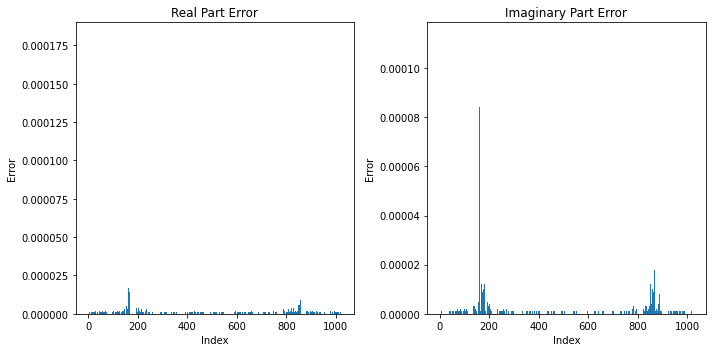

In [9]:
plt.figure(figsize=(10, 5))
plt.subplot(1,2,1)
plt.bar(ind,real_error)
plt.title("Real Part Error")
plt.xlabel("Index")
plt.ylabel("Error")
#plt.xticks(ind)
plt.tight_layout()

plt.subplot(1,2,2)
plt.bar(ind,imag_error)
plt.title("Imaginary Part Error")
plt.xlabel("Index")
plt.ylabel("Error")
#plt.xticks(ind)
plt.tight_layout()

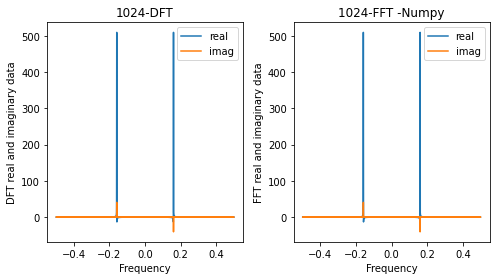

In [10]:
freq=np.fft.fftfreq(1024)

plt.figure(figsize=(7, 4))
plt.subplot(1,2,1)
plt.plot(freq,out_r,label='real')
plt.plot(freq,out_i,label='imag')
plt.title("1024-DFT")
plt.xlabel("Frequency")
plt.ylabel("DFT real and imaginary data")
plt.legend()
plt.tight_layout()
plt.subplot(1,2,2)
plt.plot(freq,golden_op.real,label='real')
plt.plot(freq,golden_op.imag,label='imag')
plt.title("1024-FFT -Numpy")
plt.xlabel("Frequency")
plt.ylabel("FFT real and imaginary data")
plt.legend()
plt.tight_layout()
plt.show()